<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 3 of 3</b>: IV. Open-Ended Section, V. Deployment. It reads the prepared training data of Notebook 1 (<b>data/interim</b>) and the final model chosen in Notebook 2 (<b>logs/final_model.json</b>). test.csv is read only in Section V.</p>

</div>

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_validate

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import preprocessing as prep
from preprocessing import TARGET, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 130)

In [2]:
final_model = json.loads(Path("../logs/final_model.json").read_text(encoding="utf-8"))
FINAL_NUMERIC = final_model["numeric"]
FINAL_FLAGS = final_model["flags"]
FINAL_CATEGORICAL = final_model["categorical"]
THRESHOLD = final_model["threshold"]


# the pipeline chosen in Notebook 2, optionally on a different set of variables
def build_final_pipeline(numeric=FINAL_NUMERIC, flags=FINAL_FLAGS, categorical=FINAL_CATEGORICAL):
    model = LogisticRegression(max_iter=5000, **final_model["parameters"])
    return prep.build_pipeline(model, numeric, flags, categorical)


train = prep.load_interim("../data/interim")
development, holdout, inner_folds = prep.split_development_holdout(train)
X_dev, y_dev = development.drop(columns=TARGET), development[TARGET]
X_holdout, y_holdout = holdout.drop(columns=TARGET), holdout[TARGET]

holdout_pipeline = build_final_pipeline().fit(X_dev, y_dev)
holdout_probability = holdout_pipeline.predict_proba(X_holdout)[:, 1]
holdout_prediction = (holdout_probability >= THRESHOLD).astype(int)
print(f"Final model: {final_model['model']}, {final_model['parameters']}, threshold {THRESHOLD}, "
      f"{len(FINAL_NUMERIC + FINAL_FLAGS + FINAL_CATEGORICAL)} variables")
print(f"Holdout F1 {f1_score(y_holdout, holdout_prediction):.4f} "
      f"(Notebook 2: {final_model['holdout_f1']})")

Final model: Logistic regression, {'C': 0.003}, threshold 0.5, 21 variables
Holdout F1 0.7836 (Notebook 2: 0.7836)


<a id="open-ended"></a>

<h1>IV. Open-Ended Section</h1>

<h2>Objectives for the Section and description of the actions taken</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Section III ends with one number, the F1. A sales manager can not act on a number alone, so this section answers four questions before the model is used.</p>
<ul>
  <li><b>Objective 1, drivers</b>: which information does the prediction rest on? --> every group of variables is removed from the final set and used alone (comparison of feature sets, 4 time folds)</li>
  <li><b>Objective 2, errors</b>: for which customers is the prediction unreliable? --> precision, recall and error rate by customer segment (holdout)</li>
  <li><b>Objective 3, probabilities</b>: can customers be ranked by their probability? --> calibration, then a contact list built from the lowest probabilities (holdout)</li>
  <li><b>Objective 4, tool</b>: why does the model say this for one purchase? --> a function that returns the probability and its five main reasons</li>
  <li>Objectives 2 to 4 use the model fitted on the development part and the <b>holdout</b>, so every result is measured on purchases the model has never seen</li>
</ul>

</div>

<h2>Results and discussion of main findings → key takeaways</h2>

<h3>Objective 1: which information drives the prediction?</h3>

In [3]:
# groups of variables for the ablation
final_variables = FINAL_NUMERIC + FINAL_FLAGS + FINAL_CATEGORICAL
variable_groups = {
    "Purchase counts (30 to 365 days)": prep.ROLLING_COUNT,
    "Supplied history (gaps, tenure, values)": prep.HISTORY_TIMING + prep.HISTORY_VALUE,
    "Customer history (new)": prep.CUSTOMER_HISTORY,
    "Current invoice": prep.CURRENT_INVOICE + prep.ROW_FEATURES + prep.ROW_FLAGS,
    "Month": ["month"],
    "Payment type and salesperson": ["payment_type", "salesperson"],
    "clientes.csv": prep.CLIENTES_CATEGORIES + prep.CLIENTES_FLAGS,
}
variable_groups = {name: [variable for variable in variables if variable in final_variables]
                   for name, variables in variable_groups.items()}
for name, variables in variable_groups.items():
    print(f"{name} ({len(variables)}): {', '.join(variables)}")

Purchase counts (30 to 365 days) (3): purchase_count_90d, purchase_count_180d, purchase_count_365d
Supplied history (gaps, tenure, values) (4): customer_tenure_days, prior_mean_gap_days, prior_std_purchase_value, prior_max_purchase_value
Customer history (new) (3): prior_repeat_share, same_season_last_year, same_season_two_years_ago
Current invoice (6): Total Imp_, Total Desc_ Global, N_ Detalhes, invoice_count_current_purchase, discount_rate, zero_cost
Month (1): month
Payment type and salesperson (2): payment_type, salesperson
clientes.csv (2): country_or_region, island_known


In [4]:
SCORING = {"f1": "f1", "auc": "roc_auc"}


# F1 and AUC of the final model on the 4 time folds, using only the given variables
def score_variables(variables):
    pipeline = build_final_pipeline([variable for variable in variables if variable in FINAL_NUMERIC],
                                    [variable for variable in variables if variable in FINAL_FLAGS],
                                    [variable for variable in variables if variable in FINAL_CATEGORICAL])
    return cross_validate(pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING, n_jobs=-1)


full_scores = score_variables(final_variables)
ablation = {}
for name, group in variable_groups.items():
    without_group = score_variables([variable for variable in final_variables if variable not in group])
    only_group = score_variables(group)
    auc_loss = full_scores["test_auc"] - without_group["test_auc"]
    ablation[name] = {"AUC lost": auc_loss.mean(), "Folds with a loss": (auc_loss > 0).sum(),
                      "F1 without": without_group["test_f1"].mean(),
                      "AUC alone": only_group["test_auc"].mean(),
                      "F1 alone": only_group["test_f1"].mean()}
ablation = pd.DataFrame(ablation).T.sort_values("AUC lost", ascending=False)

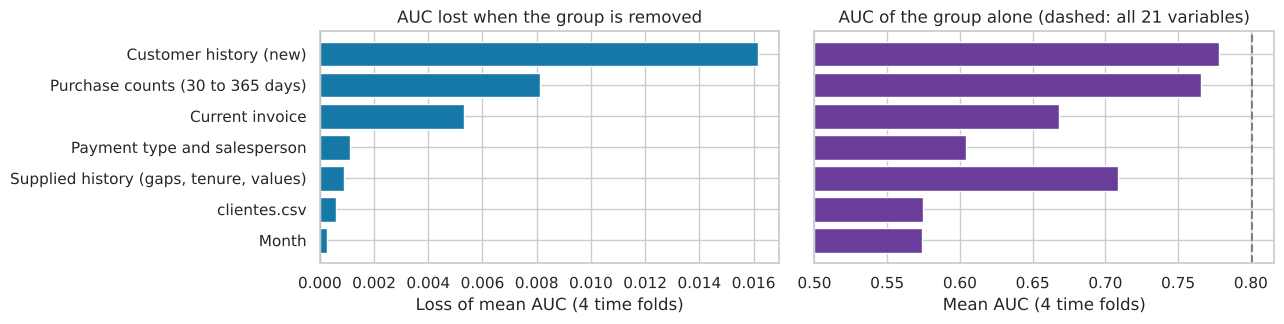

All 21 variables: AUC 0.8009, F1 0.7554
Customer history (new): AUC lost 0.0161 (in 4 of 4 folds), F1 without it 0.7428, alone: AUC 0.7784, F1 0.7539
Purchase counts (30 to 365 days): AUC lost 0.0081 (in 2 of 4 folds), F1 without it 0.7541, alone: AUC 0.7660, F1 0.7318
Current invoice: AUC lost 0.0053 (in 4 of 4 folds), F1 without it 0.7500, alone: AUC 0.6684, F1 0.7012
Payment type and salesperson: AUC lost 0.0011 (in 3 of 4 folds), F1 without it 0.7542, alone: AUC 0.6044, F1 0.7025
Supplied history (gaps, tenure, values): AUC lost 0.0009 (in 3 of 4 folds), F1 without it 0.7523, alone: AUC 0.7086, F1 0.7258
clientes.csv: AUC lost 0.0006 (in 3 of 4 folds), F1 without it 0.7537, alone: AUC 0.5745, F1 0.7116
Month: AUC lost 0.0003 (in 2 of 4 folds), F1 without it 0.7505, alone: AUC 0.5739, F1 0.7116


In [5]:
# AUC lost without a group (left) and AUC of the group alone (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
order = ablation.index[::-1]
axes[0].barh(order, ablation.loc[order, "AUC lost"], color=PLOT_BLUE)
axes[0].axvline(0, color="grey")
axes[0].set(title="AUC lost when the group is removed", xlabel="Loss of mean AUC (4 time folds)")
axes[1].barh(order, ablation.loc[order, "AUC alone"] - 0.5, left=0.5, color=PLOT_PURPLE)
axes[1].axvline(full_scores["test_auc"].mean(), color="grey", linestyle="--")
axes[1].set(title="AUC of the group alone (dashed: all 21 variables)", xlabel="Mean AUC (4 time folds)")
plt.tight_layout()
plt.show()
print(f"All 21 variables: AUC {full_scores['test_auc'].mean():.4f}, "
      f"F1 {full_scores['test_f1'].mean():.4f}")
for name, row in ablation.iterrows():
    print(f"{name}: AUC lost {row['AUC lost']:.4f} (in {row['Folds with a loss']:.0f} of 4 folds), "
          f"F1 without it {row['F1 without']:.4f}, alone: AUC {row['AUC alone']:.4f}, "
          f"F1 {row['F1 alone']:.4f}")

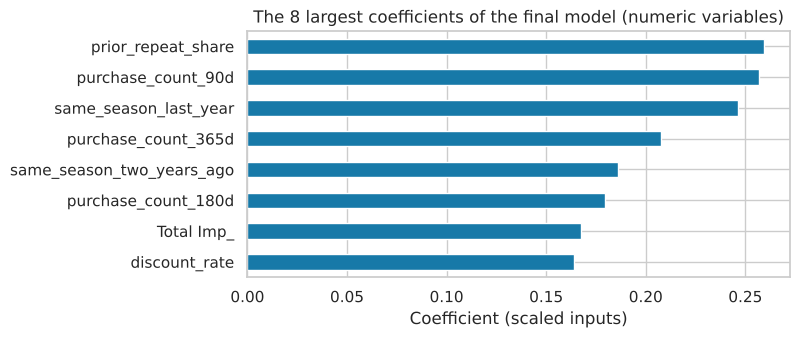

Largest coefficients: {'prior_repeat_share': 0.26, 'purchase_count_90d': 0.26, 'same_season_last_year': 0.25, 'purchase_count_365d': 0.21, 'same_season_two_years_ago': 0.19, 'purchase_count_180d': 0.18, 'Total Imp_': 0.17, 'discount_rate': 0.16}
Coefficients of the 12 months: -0.10 (month_Mar) to 0.08 (month_Sep)


In [6]:
# coefficients of the final model: all inputs are scaled, so their size can be compared
encoded_names = holdout_pipeline["prep"].get_feature_names_out()
coefficients = pd.Series(holdout_pipeline["model"].coef_[0], index=encoded_names)
numeric_coefficients = coefficients[coefficients.index.isin(FINAL_NUMERIC + FINAL_FLAGS)]
strongest = numeric_coefficients.reindex(numeric_coefficients.abs().sort_values().index).tail(8)
month_coefficients = coefficients[coefficients.index.str.startswith("month_")]

colors = np.where(strongest > 0, PLOT_BLUE, PLOT_PURPLE)
ax = strongest.plot(kind="barh", color=colors, figsize=(7, 3.2))
ax.set(title="The 8 largest coefficients of the final model (numeric variables)",
       xlabel="Coefficient (scaled inputs)", ylabel="")
plt.show()
print("Largest coefficients:", strongest[::-1].round(2).to_dict())
print(f"Coefficients of the 12 months: {month_coefficients.min():.2f} ({month_coefficients.idxmin()}) "
      f"to {month_coefficients.max():.2f} ({month_coefficients.idxmax()})")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>The customer history we built is the most valuable group</b>: without its 3 variables the AUC falls from 0.8009 to 0.7848 (in 4 of 4 folds) and the F1 from 0.7554 to 0.7428. Alone, these 3 variables reach an F1 of 0.7539</li>
  <li>The <b>purchase counts</b> are second (AUC lost 0.0081, alone 0.766). The <b>current invoice</b> is weak alone (0.668) but costs 0.0053 AUC in 4 of 4 folds, so discount and invoice size add something the history does not have</li>
  <li>Payment type and salesperson, the supplied history, clientes.csv and the month each cost at most 0.0011 AUC</li>
  <li>The <b>coefficients</b> agree: the six largest all describe the purchase rhythm (<b>prior_repeat_share</b>, <b>purchase_count_90d</b>, <b>same_season_last_year</b>, <b>purchase_count_365d</b>, <b>same_season_two_years_ago</b>, <b>purchase_count_180d</b>), then <b>Total Imp_</b> and <b>discount_rate</b></li>
  <li>The <b>month</b> matters little (coefficients from -0.10 to 0.08, AUC lost 0.0003): the season features describe when <i>this</i> customer usually buys, which leaves little for a calendar effect that is the same for everybody</li>
</ul>

</div>

<h3>Objective 2: for which customers is the prediction unreliable?</h3>

In [7]:
# scores of the final model for the holdout rows of one segment
def segment_scores(mask):
    truth, predicted = y_holdout[mask], holdout_prediction[mask]
    return {"Rows": int(mask.sum()), "Repeat rate": truth.mean(),
            "Predicted repeat rate": predicted.mean(),
            "Precision": precision_score(truth, predicted, zero_division=0),
            "Recall": recall_score(truth, predicted, zero_division=0),
            "F1": f1_score(truth, predicted, zero_division=0),
            "Error rate": (truth != predicted).mean()}


frequency_labels = ["0-1 purchases", "2-3 purchases", "4-7 purchases", "8-15 purchases",
                    "16+ purchases"]
frequency = pd.cut(X_holdout["purchase_count_365d"], [-1, 1, 3, 7, 15, 500], labels=frequency_labels)
by_frequency = pd.DataFrame({segment: segment_scores((frequency == segment).to_numpy())
                             for segment in frequency.cat.categories}).T
by_frequency.rename_axis("Purchases in the last 365 days").round(3)

,Rows,Repeat rate,Predicted repeat rate,Precision,Recall,F1,Error rate
Purchases in the last 365 days,,,,,,,
0-1 purchases,191.0,0.283,0.063,0.500,0.111,0.182,0.283
2-3 purchases,281.0,0.448,0.256,0.625,0.357,0.455,0.384
4-7 purchases,359.0,0.666,0.855,0.723,0.929,0.813,0.284
8-15 purchases,165.0,0.909,1.000,0.909,1.000,0.952,0.091
16+ purchases,82.0,1.000,1.000,1.000,1.000,1.000,0.000


In [8]:
# holdout scores of known customers, new customers and first purchases
is_known = X_holdout["customer_id"].isin(X_dev["customer_id"]).to_numpy()
is_first = (X_holdout["prior_purchase_count"] == 0).to_numpy()
segments = {"Customers known from the development part": is_known, "New customers": ~is_known,
            "First purchases": is_first}
for name, mask in segments.items():
    scores = segment_scores(mask)
    print(f"{name}: {scores['Rows']} rows, repeat rate {scores['Repeat rate']:.3f}, "
          f"F1 {scores['F1']:.3f}, error rate {scores['Error rate']:.3f}")
print(f"All holdout rows: error rate {(y_holdout != holdout_prediction).mean():.3f}")

Customers known from the development part: 945 rows, repeat rate 0.613, F1 0.792, error rate 0.254
New customers: 133 rows, repeat rate 0.541, F1 0.707, error rate 0.293
First purchases: 35 rows, repeat rate 0.257, F1 0.000, error rate 0.257
All holdout rows: error rate 0.259


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li>25.9% of the holdout predictions are wrong, but the errors are <b>not spread evenly</b></li>
  <li><b>Frequent buyers</b>: with 8 to 15 purchases in the last year the error rate is 9.1%, with 16 or more 0%. The model predicts a repeat for all of them</li>
  <li><b>Occasional buyers</b>: with 2 to 3 purchases a year 38.4% of the predictions are wrong. These customers return in 44.8% of the cases, close to a coin flip, and the model finds 35.7% of their repeats</li>
  <li>With 0 to 1 purchases the model almost never predicts a repeat (6.3%) and finds 11.1% of the repeats</li>
  <li><b>New customers</b> (133 purchases): F1 0.707 against 0.792 for known customers. <b>First purchases</b> (35): the model never predicts a repeat (F1 0), without history it can not find the 25.7% who return</li>
  <li>--> a yes/no prediction can be trusted for customers with 8 or more purchases a year. For the others the probability is the more honest output (Objective 3)</li>
</ul>

</div>

<h3>Objective 3: can the probabilities be used to contact the right customers?</h3>

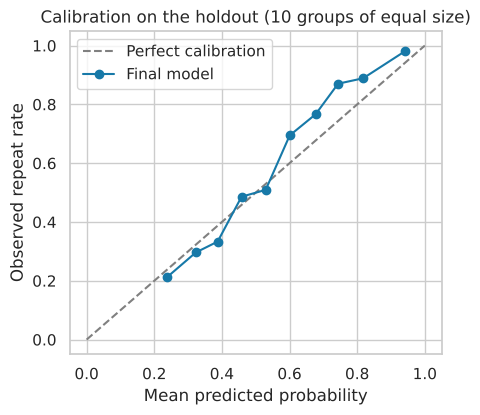

Brier score of the model: 0.175, of always predicting the repeat rate of the development part (0.549): 0.242
Predicted probability of the 10 groups: [0.24, 0.32, 0.39, 0.46, 0.53, 0.6, 0.68, 0.74, 0.82, 0.94]
Observed repeat rate of the 10 groups:  [0.21, 0.3, 0.33, 0.49, 0.51, 0.69, 0.77, 0.87, 0.89, 0.98]


In [9]:
# calibration: predicted probability against observed repeat rate in 10 groups
observed_rate, predicted_rate = calibration_curve(y_holdout, holdout_probability, n_bins=10,
                                                  strategy="quantile")
brier_model = brier_score_loss(y_holdout, holdout_probability)
brier_base_rate = brier_score_loss(y_holdout, np.full(len(y_holdout), y_dev.mean()))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
ax.plot(predicted_rate, observed_rate, marker="o", color=PLOT_BLUE, label="Final model")
ax.set(title="Calibration on the holdout (10 groups of equal size)",
       xlabel="Mean predicted probability", ylabel="Observed repeat rate")
ax.legend()
plt.show()
print(f"Brier score of the model: {brier_model:.3f}, of always predicting the repeat rate of the "
      f"development part ({y_dev.mean():.3f}): {brier_base_rate:.3f}")
print("Predicted probability of the 10 groups:", predicted_rate.round(2).tolist())
print("Observed repeat rate of the 10 groups: ", observed_rate.round(2).tolist())

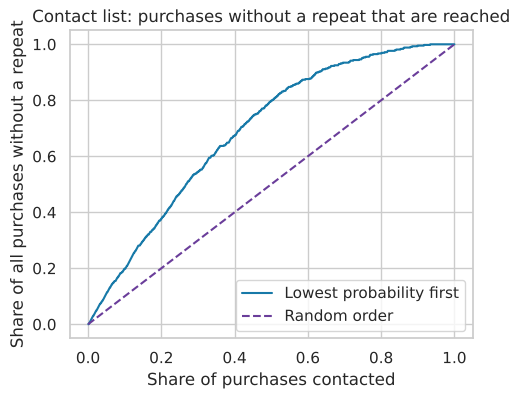

Lowest 10%: 78.5% of them do not repeat, 19.7% of all purchases without a repeat are reached
Lowest 30%: 71.8% of them do not repeat, 54.3% of all purchases without a repeat are reached
Lowest 50%: 63.3% of them do not repeat, 79.9% of all purchases without a repeat are reached
Purchases without a repeat in the whole holdout: 39.6%


In [10]:
# contact list: purchases sorted from the lowest to the highest probability of a repeat
ranked = pd.DataFrame({"probability": holdout_probability, "no_repeat": 1 - y_holdout.to_numpy()})
ranked = ranked.sort_values("probability").reset_index(drop=True)
share_contacted = (ranked.index + 1) / len(ranked)
share_reached = ranked["no_repeat"].cumsum() / ranked["no_repeat"].sum()

fig, ax = plt.subplots(figsize=(5.2, 4))
ax.plot(share_contacted, share_reached, color=PLOT_BLUE, label="Lowest probability first")
ax.plot([0, 1], [0, 1], color=PLOT_PURPLE, linestyle="--", label="Random order")
ax.set(title="Contact list: purchases without a repeat that are reached",
       xlabel="Share of purchases contacted", ylabel="Share of all purchases without a repeat")
ax.legend()
plt.show()
for share in [0.1, 0.3, 0.5]:
    contacted = ranked.iloc[:int(share * len(ranked))]
    reached = contacted["no_repeat"].sum() / ranked["no_repeat"].sum()
    print(f"Lowest {share:.0%}: {contacted['no_repeat'].mean():.1%} of them do not repeat, "
          f"{reached:.1%} of all purchases without a repeat are reached")
print(f"Purchases without a repeat in the whole holdout: {ranked['no_repeat'].mean():.1%}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>Calibration</b>: the Brier score is 0.175 against 0.242 for always predicting the repeat rate of the development part. Low probabilities are accurate (0.24 predicted, 0.21 observed in the lowest group), high ones are <b>too careful</b> (0.68 predicted, 0.77 observed), because the newest period has more repeats (0.604) than the development part (0.549)</li>
  <li><b>Contact list</b>: sorted from the lowest probability, the first 30% of the purchases contain 54.3% of all purchases without a repeat, and 71.8% of them are such purchases (39.6% in the whole holdout). The first 50% reach 79.9%</li>
  <li>--> the company should not only use the 0/1 prediction: sorting by probability lets it choose the size of a campaign</li>
</ul>

</div>

<h3>Objective 4: a tool that explains one prediction</h3>

In [11]:
# probability of a repeat purchase for one row and the variables that move it most
def explain_purchase(purchase, pipeline=holdout_pipeline, n_reasons=5):
    row = purchase.to_frame().T.infer_objects()
    encoded = pipeline["prep"].transform(row)[0]
    variables = [prep.source_variable(name, FINAL_CATEGORICAL)
                 for name in pipeline["prep"].get_feature_names_out()]
    contributions = pd.Series(encoded * pipeline["model"].coef_[0], index=variables)
    contributions = contributions.groupby(level=0).sum()
    by_size = contributions.abs().sort_values(ascending=False).index
    strongest = contributions.reindex(by_size).head(n_reasons)
    probability = pipeline.predict_proba(row)[0, 1]
    reasons = pd.DataFrame({"Value of the purchase": [purchase[variable] for variable in strongest.index],
                            "Effect on the log-odds": strongest.round(2)})
    reasons["Direction"] = np.where(strongest > 0, "more likely to repeat", "less likely to repeat")
    return probability, reasons


for position in [int(np.argmax(holdout_probability)), int(np.argmin(holdout_probability))]:
    probability, reasons = explain_purchase(X_holdout.iloc[position])
    print(f"Purchase ID {X_holdout['ID'].iloc[position]}: "
          f"probability of a repeat purchase {probability:.2f}, "
          f"prediction {int(probability >= THRESHOLD)}, what happened: {y_holdout.iloc[position]}")
    display(reasons)

Purchase ID 10000998: probability of a repeat purchase 0.98, prediction 1, what happened: 1


,Value of the purchase,Effect on the log-odds,Direction
same_season_two_years_ago,12.0,0.60,more likely to repeat
same_season_last_year,8.0,0.56,more likely to repeat
purchase_count_90d,8.0,0.54,more likely to repeat
purchase_count_365d,32.0,0.43,more likely to repeat
purchase_count_180d,15.0,0.36,more likely to repeat


Purchase ID 10003595: probability of a repeat purchase 0.12, prediction 0, what happened: 1


,Value of the purchase,Effect on the log-odds,Direction
prior_repeat_share,0.00,-0.39,less likely to repeat
prior_mean_gap_days,2524.00,-0.34,less likely to repeat
purchase_count_365d,0.00,-0.32,less likely to repeat
Total Imp_,7.25,-0.24,less likely to repeat
purchase_count_180d,0.00,-0.22,less likely to repeat


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>explain_purchase</b> returns the probability of one purchase and the five variables that move it most (coefficient times scaled value, summed over the one-hot columns of a category). This only works because the final model is linear, one more reason for its choice</li>
  <li>Purchase 10000998 gets 0.98: the customer bought 12 and 8 times in the same season of the last two years. Purchase 10003595 gets 0.12 (no earlier repeat, mean gap of 2,524 days), but the customer did come back, an example of the occasional buyers of Objective 2</li>
</ul>

</div>

<h3>Key takeaways</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Drivers</b>: the purchase rhythm drives the prediction. Three history variables alone reach an F1 of 0.754 against 0.755 for all 21 --> the purchase dates of a customer are the data that matters</li>
  <li><b>Errors</b>: reliable for customers with 8 or more purchases a year (at most 9% errors), unreliable for occasional buyers (38%) and blind for first purchases</li>
  <li><b>Probabilities</b>: the ranking is reliable (the lowest 30% contain 54% of the purchases without a repeat), the high probabilities are too low in the newest period</li>
  <li><b>Tool</b>: one function explains any single prediction</li>
  <li>Limits: the holdout is one period of 1,078 purchases and some segments are small (35 first purchases)</li>
</ul>

</div>

<a id="deployment"></a>

<h1>V. Deployment</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>This is the <b>first and only use of test.csv</b> in the project: the finished model is applied to it. The function starts from the raw files and runs every step in the same order: the row rules of Notebook 1 (<b>prepare_purchases</b>), the pipeline chosen in Notebook 2, fitted on all training rows, and the threshold. Nothing is fitted on test.csv and no rule was derived from it.</p>

</div>

In [12]:
# raw train.csv, clientes.csv and test.csv to one prediction for every row of test.csv
def predict_repeat_purchases(raw_folder="../data/raw"):
    raw_train, clientes = prep.load_train(raw_folder)
    raw_test = pd.read_csv(f"{raw_folder}/test.csv")
    prepared_train, prepared_test = prep.prepare_purchases(raw_train, clientes, new_purchases=raw_test)
    pipeline = build_final_pipeline().fit(prepared_train, prepared_train[TARGET])
    probability = pipeline.predict_proba(prepared_test)[:, 1]
    submission = pd.DataFrame({"ID": prepared_test["ID"],
                               TARGET: (probability >= THRESHOLD).astype(int)})
    return submission, probability, prepared_train, prepared_test


submission, test_probability, prepared_train, prepared_test = predict_repeat_purchases()
submission.head()

,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,0
3,10000020,0
4,10000025,1


In [13]:
# checks of the predictions against sample_submission.csv
sample_submission = pd.read_csv("../data/raw/sample_submission.csv")
test_matrix = holdout_pipeline["prep"].transform(prepared_test)

checks = {
    "One prediction for every row of sample_submission.csv": len(submission) == len(sample_submission),
    "IDs and their order equal sample_submission.csv": submission["ID"].equals(sample_submission["ID"]),
    "Column names equal sample_submission.csv":
        list(submission.columns) == list(sample_submission.columns),
    "Predictions are only 0 or 1": bool(submission[TARGET].isin([0, 1]).all()),
    "Training rows are prepared exactly as in Notebook 1": prepared_train.equals(train),
    "No missing value after the pre-processing": not np.isnan(test_matrix).any(),
}
for check, passed in checks.items():
    print(f"{check}: {passed}")

One prediction for every row of sample_submission.csv: True
IDs and their order equal sample_submission.csv: True
Column names equal sample_submission.csv: True
Predictions are only 0 or 1: True
Training rows are prepared exactly as in Notebook 1: True
No missing value after the pre-processing: True


In [14]:
Path("../results").mkdir(exist_ok=True)
submission.to_csv("../results/Group30_submission.csv", index=False)
print(f"Saved results/Group30_submission.csv with {len(submission)} predictions")
print(f"Share of predicted repeats in test.csv: {submission[TARGET].mean():.3f} "
      f"(holdout: {holdout_prediction.mean():.3f}), mean probability: {test_probability.mean():.3f}")

# a first look at test.csv, after the predictions are made
days_between = (pd.to_datetime(prepared_test["purchase_date"]).min()
                - pd.to_datetime(prepared_train["purchase_date"]).max()).days
print(f"test.csv: {prepared_test['purchase_date'].min()} to {prepared_test['purchase_date'].max()}, "
      f"it starts {days_between} days after the end of train.csv")
print(f"First purchases in test.csv: {(prepared_test['prior_purchase_count'] == 0).mean():.1%}, "
      f"in train: {(train['prior_purchase_count'] == 0).mean():.1%}")

Saved results/Group30_submission.csv with 986 predictions
Share of predicted repeats in test.csv: 0.650 (holdout: 0.592), mean probability: 0.605
test.csv: 2025-05-24 to 2026-10-06, it starts 98 days after the end of train.csv
First purchases in test.csv: 2.2%, in train: 9.3%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Result</b></p>
<ul>
  <li><b>predict_repeat_purchases</b> returns one prediction for each of the 986 rows of test.csv. All six checks pass: IDs and order equal sample_submission.csv, and the training rows come out exactly as in Notebook 1, so adding test.csv changes nothing in the training data</li>
  <li>The function is safe for new data: impossible values are repaired by rule, missing values get the training median or the level "missing", new category levels join the rare levels, and no row of a new file is dropped</li>
  <li>The model predicts a repeat for <b>65.0%</b> of the test purchases (holdout 59.2%). This is plausible: only 2.2% of the test rows are first purchases (9.3% in train)</li>
  <li>Limitation seen only now: test.csv starts 98 days after train.csv ends. Purchases of these days are not in the data, so the history of some test rows is incomplete</li>
  <li><b>results/Group30_submission.csv</b> is the file we selected on Kaggle. It scores <b>0.79892</b> on the public leaderboard, close to the 0.78 we expected from the holdout</li>
  <li><b>Note on the public leaderboard</b>: it is computed on a part of test.csv only, so small differences between two submissions are noise. The model was chosen on the time folds and never by the leaderboard score. The final ranking uses the rest of test.csv, where a strongly regularised model on 21 variables has little room to have overfitted</li>
</ul>

</div>